In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/Sjakkprosjekt/games.csv')
data.shape

(20058, 16)

In [ ]:
print(data.duplicated().sum())
print(data["id"].duplicated().sum())

429
945


In [ ]:
data = data.drop_duplicates(subset='id')
data.shape

(19113, 16)

In [ ]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data['winner'])
train.shape, test.shape

((15290, 16), (3823, 16))

Sjekker om ratinforskjellen betyr noe for hvem som vinner

In [ ]:
train['rating_diff'] = train['white_rating'] - train['black_rating']
train.groupby('winner')['rating_diff'].mean()

,rating_diff
winner,
black,-87.670075
draw,6.883099
white,93.457046


Tallene viser her at den sterkeste spillerene vinner oftest og at remis skjer mest når spillerne er jevne, med ca 7 poeng forskjell bare.

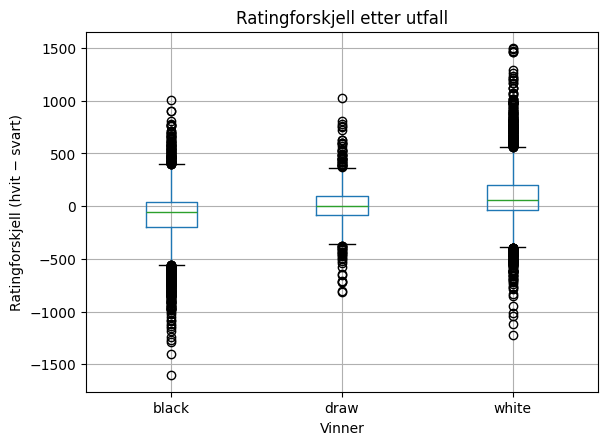

In [ ]:
import matplotlib.pyplot as plt

ax = train.boxplot(column='rating_diff', by='winner')
ax.set_ylabel('Ratingforskjell (hvit − svart)')
ax.set_xlabel('Vinner')
ax.set_title('Ratingforskjell etter utfall')
plt.suptitle('')
plt.show()

Nå går vi over til tidskontrollen og ser på den

In [ ]:
train['increment_code'].value_counts().head(10)

,count
increment_code,
10+0,5885
15+0,1016
15+15,674
5+5,581
5+8,531
8+0,454
10+5,418
20+0,338
15+10,331


De fleste spillene er på 10 minutter uten ekstra tid  per trekk. Alt her klasifiseres under hurtigsjakk. Vi må deretter gjøre om teksten om til tall

In [ ]:
train['minutes'] = train['increment_code'].str.split('+').str[0].astype(int)
train['minutes'].describe()

,minutes
count,15290.000000
mean,13.788489
std,17.208528
min,0.000000
25%,10.000000
50%,10.000000
75%,15.000000
max,180.000000


In [ ]:
train['type'] = pd.cut(train['minutes'], bins=[-1, 5, 29, 999], labels=['lyn', 'hurtig', 'klassisk'])
train.groupby('type')['winner'].value_counts(normalize=True)

/tmp/ipykernel_1122/2634438542.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train.groupby('type')['winner'].value_counts(normalize=True)


type      winner
lyn       white     0.486571
          black     0.472205
          draw      0.041224
hurtig    white     0.501258
          black     0.453459
          draw      0.045283
klassisk  white     0.496388
          black     0.433437
          draw      0.070175
Name: proportion, dtype: float64

In [ ]:
train['type'].value_counts()

,count
type,
hurtig,12720
lyn,1601
klassisk,969


En åpning er de første trekkene i partiet, og de har navn, for eksempel «Sicilian Defense». Datasettet har to kolonner for dette:

opening_name: fullt navn, med mange varianter
opening_eco: en kort kode som B20, der én kode dekker en gruppe like åpninger

In [ ]:
print(train['opening_name'].nunique())
print(train['opening_eco'].nunique())

1384
353


ECO-koden starter alltid med en bokstav fra A til E, og bokstaven sier hvilken familie åpningen hører til:

A: flankeåpninger (f.eks. 1.c4, 1.Nf3)
B: halvåpne forsvar (f.eks. Siciliansk, 1.e4 c5)
C: åpne spill (1.e4 e5) og fransk
D: lukkede spill (1.d4 d5)
E: indiske forsvar (1.d4 Nf6)
dette endrer opening_eco fra 353 til 5 kategorier

In [ ]:
train['eco_group'] = train['opening_eco'].str[0]
train.groupby('eco_group')['winner'].value_counts(normalize=True)

eco_group  winner
A          white     0.480211
           black     0.471966
           draw      0.047823
B          white     0.490000
           black     0.460500
           draw      0.049500
C          white     0.518909
           black     0.439130
           draw      0.041962
D          white     0.495644
           black     0.456922
           draw      0.047435
E          white     0.476309
           black     0.458853
           draw      0.064838
Name: proportion, dtype: float64

In [ ]:
train.groupby('rated')['winner'].value_counts(normalize=True)

rated  winner
False  white     0.506849
       black     0.438699
       draw      0.054452
True   white     0.497656
       black     0.457801
       draw      0.044543
Name: proportion, dtype: float64

Ikke store forskjeller på åpningsstrategier eller om det er formelle partier som er spilt, noe som lener at Elo formelen er det som bestemmer mest. Dette er ikke sjokkerende. Men spørsmålet blir om disse featurene til sammen med elo formelen vil gi bedre resultat enn elo formelen alene?

Nå har vi utforsket alle de viktige featurene så nå begynner vi på modell testing. Starter med å klargjøre featurene

eco_group blir gjort om til tall verdier ved hjelp av one hot encoding.

In [ ]:
def lag_features(df):
    X = pd.DataFrame(index=df.index)
    X['rating_diff'] = df['white_rating'] - df['black_rating']
    X['snitt_rating'] = (df['white_rating'] + df['black_rating']) / 2
    X['minutes'] = df['increment_code'].str.split('+').str[0].astype(int)
    X['increment'] = df['increment_code'].str.split('+').str[1].astype(int)
    X['rated'] = df['rated'].astype(int)
    eco = df['opening_eco'].str[0]
    for bokstav in ['A', 'B', 'C', 'D', 'E']:
        X['eco_' + bokstav] = (eco == bokstav).astype(int)
    return X

X_train = lag_features(train)
X_train.head()

,rating_diff,snitt_rating,minutes,increment,rated,eco_A,eco_B,eco_C,eco_D,eco_E
16780,127,1587.5,15,5,1,1,0,0,0,0
7664,0,1352.0,15,0,1,0,0,1,0,0
19679,-287,1149.5,5,5,0,0,1,0,0,0
13088,227,1838.5,10,1,1,0,0,0,1,0
13485,139,1802.5,10,0,1,0,1,0,0,0


In [ ]:
y_train = train['winner']
X_test = lag_features(test)
y_test = test['winner']

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(15290, 10) (15290,)
(3823, 10) (3823,)


Begynner med moddellering. Starter med den enkleste og "dummeste" modellen som ignorer alt og bare gir på sansynligheten.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

dummy = DummyClassifier(strategy='prior')
ll = cross_val_score(dummy, X_train, y_train, cv=5, scoring='neg_log_loss')
acc = cross_val_score(dummy, X_train, y_train, cv=5, scoring='accuracy')

print('Log loss:', -ll.mean())
print('Treff:', acc.mean())

Log loss: 0.8477692363400205
Treff: 0.49941137998691965


Funksjon for elo formelen under. Dette er hva vi prøver å slå.

In [ ]:
import numpy as np
from sklearn.metrics import log_loss, accuracy_score

def elo_sannsynlighet(rating_diff, p_remis):
    E = 1 / (1 + 10 ** (-rating_diff / 400))
    p_hvit = np.clip(E - p_remis / 2, 0.001, 1)
    p_svart = np.clip(1 - E - p_remis / 2, 0.001, 1)
    p = np.column_stack([p_svart, np.full(len(E), p_remis), p_hvit])
    return p / p.sum(axis=1, keepdims=True)

p_remis = (y_train == 'draw').mean()
p_elo = elo_sannsynlighet(X_train['rating_diff'], p_remis)

print('Log loss:', log_loss(y_train, p_elo, labels=['black', 'draw', 'white']))
print('Treff:', accuracy_score(y_train, np.array(['black', 'draw', 'white'])[p_elo.argmax(axis=1)]))

Log loss: 0.8034753901027305
Treff: 0.6212557226945716


Elo formelen slår den "dumme" modellen. Elo treffer altså 62% bare ved å se på raingforskjellen.

Vi begynner nå med ekte modell. Logistisk regresjon.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

ll = cross_val_score(logreg, X_train, y_train, cv=5, scoring='neg_log_loss')
acc = cross_val_score(logreg, X_train, y_train, cv=5, scoring='accuracy')
print('Log loss:', -ll.mean())
print('Treff:', acc.mean())

Log loss: 0.7748878691157244
Treff: 0.620209287115762


Se der! Allerede er Elo-formelene slått bare ved hjelp av en logistisk regresjons modell. Treffprosenten er fremdeles lik, men logistisk regresjon er mer sikker så vi får en lavere log loss!

Fortsetter å teste flere modeller.
Gradient boosting:

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb = HistGradientBoostingClassifier(random_state=42)

ll = cross_val_score(gb, X_train, y_train, cv=5, scoring='neg_log_loss')
acc = cross_val_score(gb, X_train, y_train, cv=5, scoring='accuracy')
print('Log loss:', -ll.mean())
print('Treff:', acc.mean())

Log loss: 0.776726983727753
Treff: 0.6155657292347939


Omtrent like god som logistisk regresjon. SÅ mer avanserte modeller gir ikke bedre svar.
Gradient boosting har hyperparametere som vi kan prøve finjustere for å se om vi får bedre svar.

In [ ]:
from sklearn.model_selection import GridSearchCV

params = {
    'learning_rate': [0.01, 0.04],
    'max_leaf_nodes': [4, 12],
    'min_samples_leaf': [20],
}
sok = GridSearchCV(HistGradientBoostingClassifier(random_state=42), params, cv=5, scoring='neg_log_loss')
sok.fit(X_train, y_train)

print('Beste innstillinger:', sok.best_params_)
print('Log loss:', -sok.best_score_)

Beste innstillinger: {'learning_rate': 0.04, 'max_leaf_nodes': 12, 'min_samples_leaf': 20}
Log loss: 0.7724547418026508


Her ble den litt bedre med 0.772, noe som slår logistisk sin på 0.774.
Vi fortsetter og tester med fler modeller
Random forest:

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, random_state=42, n_jobs=-1)

ll = cross_val_score(rf, X_train, y_train, cv=5, scoring='neg_log_loss')
acc = cross_val_score(rf, X_train, y_train, cv=5, scoring='accuracy')
print('Log loss:', -ll.mean())
print('Treff:', acc.mean())

Log loss: 0.7745655545099771
Treff: 0.6141922825376063


Igjen får vi 0.774. Dette tyder på at grensen ligger i dataen og ikke i modellen.
Men vi tester et siste før vi går videre.
Nevrale nettverk:

In [ ]:
from sklearn.neural_network import MLPClassifier

mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), max_iter=500, random_state=42))

ll = cross_val_score(mlp, X_train, y_train, cv=5, scoring='neg_log_loss')
print('Log loss:', -ll.mean())

Log loss: 0.7739108702058832


En finjustert gradient boosting gir oss best resultat.

Nå kan vi gå over på å testsettet.

In [ ]:
beste = sok.best_estimator_

p_test = beste.predict_proba(X_test)
print('Modell log loss:', log_loss(y_test, p_test, labels=beste.classes_))
print('Modell treff:', accuracy_score(y_test, beste.predict(X_test)))

p_elo_test = elo_sannsynlighet(X_test['rating_diff'], p_remis)
print('Elo log loss:', log_loss(y_test, p_elo_test, labels=['black', 'draw', 'white']))
print('Elo treff:', accuracy_score(y_test, np.array(['black', 'draw', 'white'])[p_elo_test.argmax(axis=1)]))

Modell log loss: 0.7651427895888998
Modell treff: 0.6225477373790217
Elo log loss: 0.786861053201825
Elo treff: 0.6220245880198797


Modellen slår elo formelen!
Nå finne ut av hvilke features modellen faktisk bruker.
vi stokker om en kolonne om gangen, slik at verdiene havner på feil partier, og ser hvor mye dårligere log loss blir. Blir modellen mye dårligere, var featuren viktig. Endrer ingenting seg, brukte modellen den knapt.



In [ ]:
from sklearn.inspection import permutation_importance

res = permutation_importance(beste, X_test, y_test, scoring='neg_log_loss', n_repeats=10, random_state=42)
viktighet = pd.Series(res.importances_mean, index=X_test.columns).sort_values(ascending=False)
viktighet

,0
rating_diff,0.165000
snitt_rating,0.004085
rated,0.001948
eco_D,0.000273
eco_A,0.000214
minutes,0.000017
eco_E,0.000005
eco_B,-0.000083
eco_C,-0.000243
increment,-0.000715


rating_diff dominerer her, mens rating_snitt og rated hjelper litt.


Lagrer modellen

In [ ]:
import joblib
joblib.dump(beste, '/content/drive/MyDrive/Sjakkprosjekt/modell.joblib')

['/content/drive/MyDrive/Sjakkprosjekt/modell.joblib']

Begynner på nettsiden

In [ ]:
def spaa(hvit_rating, svart_rating, minutter, tillegg, ratet, aapning):
    df = pd.DataFrame([{
        'white_rating': hvit_rating,
        'black_rating': svart_rating,
        'increment_code': f'{minutter}+{tillegg}',
        'rated': ratet,
        'opening_eco': aapning,
    }])
    X = lag_features(df)
    p = beste.predict_proba(X)[0]
    return dict(zip(beste.classes_, p))

spaa(1600, 1400, 10, 0, True, 'C')

{'black': np.float64(0.25149022804897575),
 'draw': np.float64(0.03297930306841708),
 'white': np.float64(0.7155304688826072)}

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr

def spaa_nettside(hvit_rating, svart_rating, minutter, tillegg, ratet, aapning):
    p = spaa(hvit_rating, svart_rating, int(minutter), int(tillegg), ratet, aapning)
    navn = {'white': 'Hvit vinner', 'draw': 'Remis', 'black': 'Svart vinner'}
    return {navn[k]: float(v) for k, v in p.items()}

app = gr.Interface(
    fn=spaa_nettside,
    inputs=[
        gr.Number(value=1500, label='Rating hvit'),
        gr.Number(value=1500, label='Rating svart'),
        gr.Number(value=10, label='Minutter per spiller'),
        gr.Number(value=0, label='Sekunder ekstra per trekk'),
        gr.Checkbox(value=True, label='Ratet parti'),
        gr.Dropdown([('A: Flankeåpninger', 'A'), ('B: Halvåpne forsvar', 'B'), ('C: Åpne spill', 'C'),
                     ('D: Lukkede spill', 'D'), ('E: Indiske forsvar', 'E')], value='C', label='Åpning'),
    ],
    outputs=gr.Label(label='Sannsynlighet'),
    title='Sjakkspåmann',
)
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6e2615a7d377a9f6e0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
acc = cross_val_score(sok.best_estimator_, X_train, y_train, cv=5, scoring='accuracy')
print('Treff:', acc.mean())

Treff: 0.6175277959450621


In [ ]:
acc = cross_val_score(mlp, X_train, y_train, cv=5, scoring='accuracy')
print('Treff:', acc.mean())

Treff: 0.6184434270765207


Lager app ut av dette

In [ ]:
%cd /content/drive/MyDrive/Sjakkprosjekt

/content/drive/MyDrive/Sjakkprosjekt


In [ ]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd

beste = joblib.load('modell.joblib')

def lag_features(df):
    X = pd.DataFrame(index=df.index)
    X['rating_diff'] = df['white_rating'] - df['black_rating']
    X['snitt_rating'] = (df['white_rating'] + df['black_rating']) / 2
    X['minutes'] = df['increment_code'].str.split('+').str[0].astype(int)
    X['increment'] = df['increment_code'].str.split('+').str[1].astype(int)
    X['rated'] = df['rated'].astype(int)
    eco = df['opening_eco'].str[0]
    for bokstav in ['A', 'B', 'C', 'D', 'E']:
        X['eco_' + bokstav] = (eco == bokstav).astype(int)
    return X

st.title('Sjakkspåmann')
st.write('Fyll inn informasjon om partiet, så viser modellen sjansen for hvert utfall.')

hvit_rating = st.number_input('Rating hvit', value=1500)
svart_rating = st.number_input('Rating svart', value=1500)
minutter = st.number_input('Minutter per spiller', value=10)
tillegg = st.number_input('Sekunder ekstra per trekk', value=0)
ratet = st.checkbox('Ratet parti', value=True)
aapninger = {'A: Flankeåpninger': 'A', 'B: Halvåpne forsvar': 'B', 'C: Åpne spill': 'C',
             'D: Lukkede spill': 'D', 'E: Indiske forsvar': 'E'}
valg = st.selectbox('Åpning', list(aapninger.keys()), index=2)

if st.button('Spå resultat'):
    df = pd.DataFrame([{'white_rating': hvit_rating, 'black_rating': svart_rating,
        'increment_code': f'{minutter}+{tillegg}', 'rated': ratet, 'opening_eco': aapninger[valg]}])
    p = beste.predict_proba(lag_features(df))[0]
    navn = {'white': 'Hvit vinner', 'draw': 'Remis', 'black': 'Svart vinner'}
    for klasse, sannsynlighet in zip(beste.classes_, p):
        st.write(f'{navn[klasse]}: {sannsynlighet:.1%}')
        st.progress(float(sannsynlighet))

Overwriting app.py


In [ ]:
import sklearn
with open('requirements.txt', 'w') as f:
    f.write(f'scikit-learn=={sklearn.__version__}\n')
    f.write('pandas\n')
    f.write('joblib\n')
    f.write('streamlit\n')
print(open('requirements.txt').read())

scikit-learn==1.6.1
pandas
joblib
streamlit

